# Dark Ecology Intelligence (DEI) — Phase 4: GloBI Investigation
## Notebook 02: Regional Data Availability Across Bengaluru, Mysuru, and Nilgiri–Bandipur

### Academic Context
Project: **Dark Ecology Intelligence: Temporal Graph Neural Networks and Deep Reinforcement Learning for AI-Driven Light Pollution Governance**  
Course: **ANN Lab PBL — AI2531A**  
Phase: **Phase 4 — GloBI Regional Feasibility and Data Availability**

---

### Objectives of this Notebook
1. Execute controlled spatial queries across our three approved 50 km × 50 km study windows:
   - **Bengaluru** (Urban): `bbox=77.3577,12.7396,77.8229,13.1959`
   - **Mysuru** (Peri-urban): `bbox=76.4242,12.0790,76.8866,12.5338`
   - **Nilgiri–Bandipur** (Forest, Option A): `bbox=76.3658,11.4286,76.8270,11.8832`
2. Audit coordinate completeness and study polygon containment.
3. Spatially join interaction records with our 100 5 km × 5 km grid cells per region.
4. Quantify temporal alignment with our approved 2012–2024 VIIRS/GBIF study baseline.
5. Catalog available interaction types and analyze bidirectional symmetry in GloBI.

In [1]:
import sys
import json
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point
from pathlib import Path
import matplotlib.pyplot as plt

# Load precomputed audit summary
summary_path = Path("../../data/metadata/phase_4_checks/globi_investigation_summary.json")
with open(summary_path, "r") as f:
    summary_data = json.load(f)

print("Loaded empirical GloBI investigation summary.")

Loaded empirical GloBI investigation summary.


### 1. Regional Record Counts & Spatial Containment
Let us review the exact record counts retrieved from GloBI for the three study windows.

In [2]:
reg_table = []
for reg_key, reg in summary_data["study_landscapes"].items():
    reg_table.append({
        "Study Window": reg["name"],
        "Landscape": reg["landscape"],
        "BBOX Retrieved": reg["total_records_retrieved"],
        "With Coordinates": reg["records_with_coordinates"],
        "Inside 50km Polygon": reg["records_inside_polygon"],
        "Outside Slivers": reg["records_outside_polygon"],
        "Assigned to 5km Grid": reg["records_assigned_to_grid"],
        "Occupied Cells": f"{reg['occupied_grid_cells']} / 100",
        "2012–2024 Records": reg["records_2012_2024"],
        "Pre-2012 Records": reg["records_pre_2012"],
        "Post-2024 Records": reg["records_post_2024"]
    })

pd.DataFrame(reg_table)

,Study Window,Landscape,BBOX Retrieved,With Coordinates,Inside 50km Polygon,Outside Slivers,Assigned to 5km Grid,Occupied Cells,2012–2024 Records,Pre-2012 Records,Post-2024 Records
0,Bengaluru,Urban,7226,7226,7222,4,7222,86 / 100,4482,590,2092
1,Mysuru,Peri-urban,946,946,946,0,946,49 / 100,574,148,212
2,Nilgiri-Bandipur,Forest,876,876,876,0,876,28 / 100,104,752,18


### 2. Spatial Grid-Cell Coverage (100-Cell Grids)
In Phase 1, we established a 100-cell 5 km grid for each landscape.
- **Bengaluru**: 86 of 100 cells contain at least 1 interaction record (high spatial diffusion across urban green spaces).
- **Mysuru**: 49 of 100 cells contain interaction records (concentrated around Chamundi Hills, lakes, and peri-urban farmlands).
- **Nilgiri–Bandipur**: 28 of 100 cells contain records (clustered within national park core zones and forest survey transects).

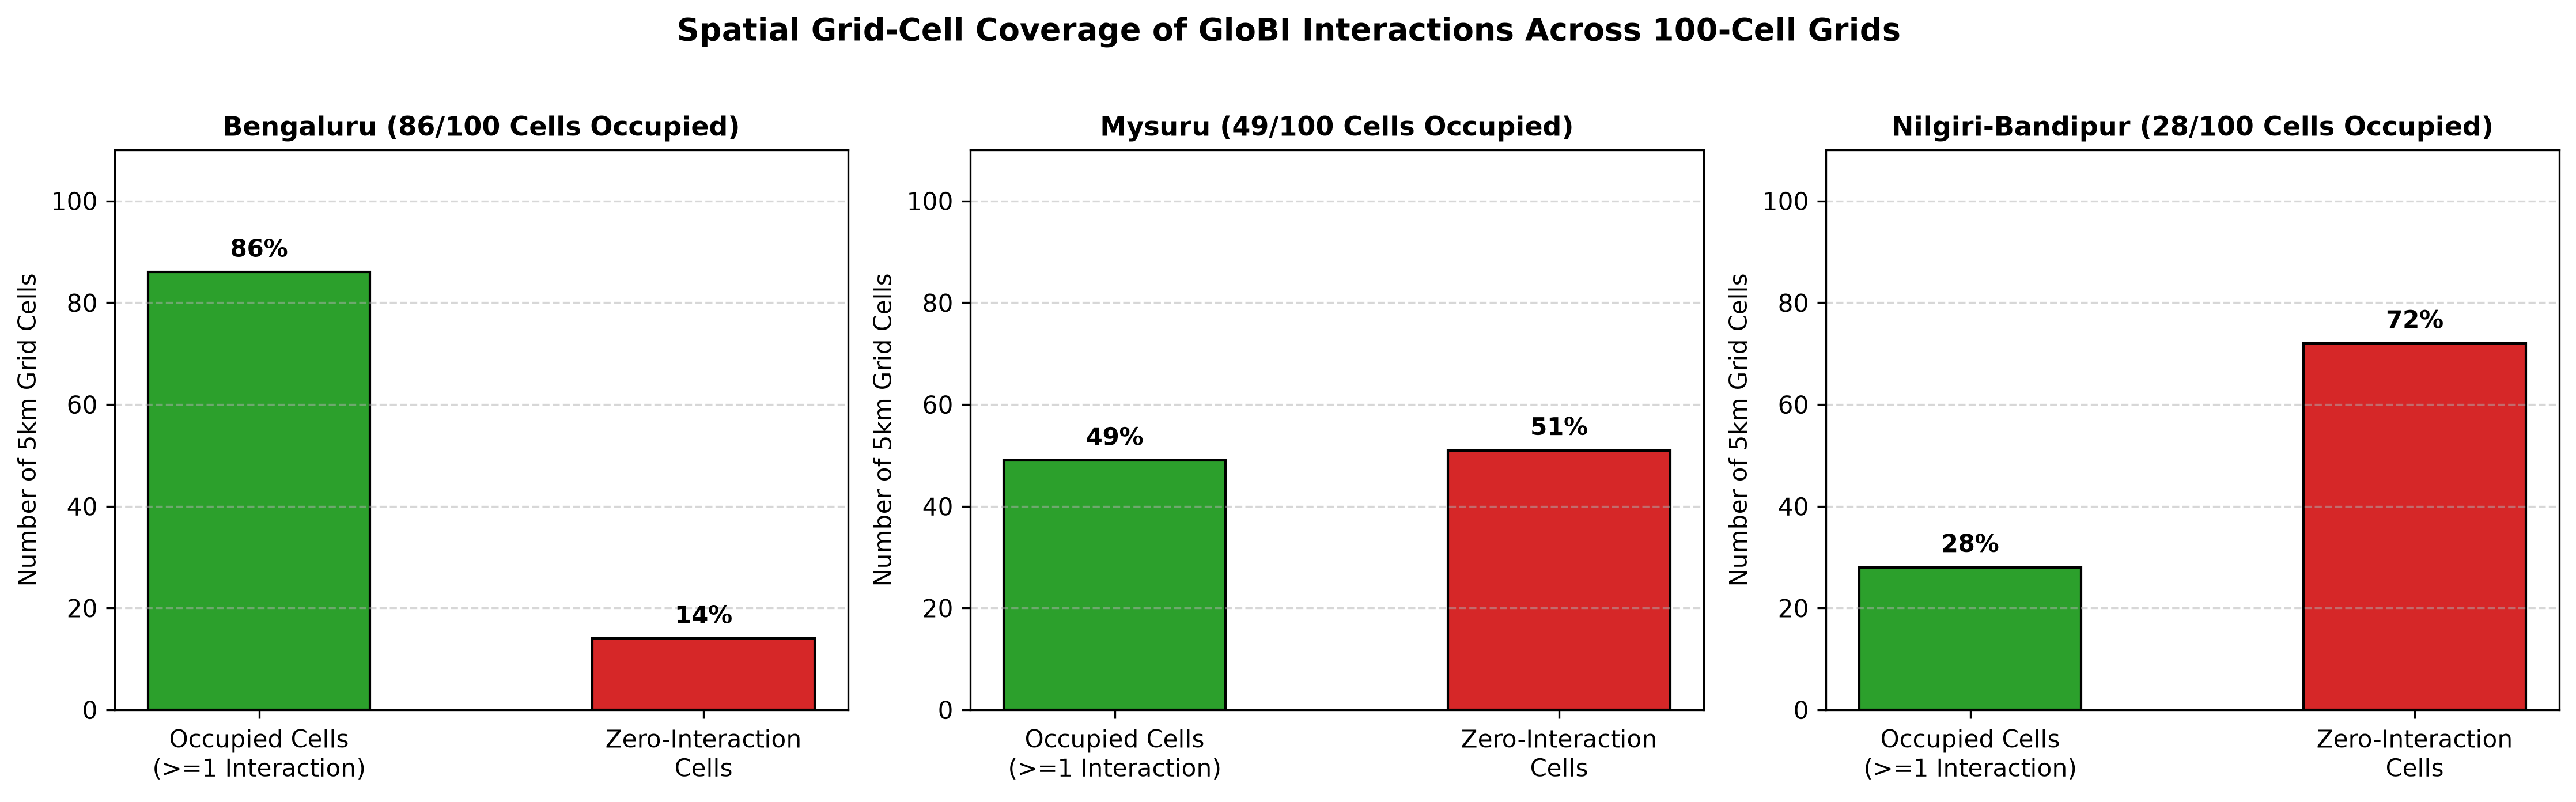

In [3]:
# Display Figure: Spatial Grid-Cell Coverage
fig_path = Path("../../reports/phase_4/figures/globi_spatial_cell_occupancy.png")
if fig_path.exists():
    from IPython.display import Image
    display(Image(filename=str(fig_path)))
else:
    print("Figure path not found.")

### 3. Interaction Types & Bidirectional Symmetry
GloBI indexes trophic interactions bidirectionally:
- When an organism A preys on organism B, GloBI indexes two predicates:
  - `A preysOn B`
  - `B preyedUponBy A`
- Similarly, feeding relationships are paired:
  - `A eats B`
  - `B eatenBy A`
- Host relationships:
  - `A hostOf B`
  - `B hasHost A`
- Floral visitation:
  - `A visitsFlowersOf B`
  - `B flowersVisitedBy A`

Let us inspect the top interaction types per landscape.

In [4]:
for reg_key, reg in summary_data["study_landscapes"].items():
    print(f"=== {reg['name']} ({reg['landscape']}) Interaction Types ===")
    itypes = pd.Series(reg["interaction_types"])
    print(itypes.head(8))
    print()

=== Bengaluru (Urban) Interaction Types ===
interactsWith      2498
eats               1974
eatenBy            1974
preyedUponBy        173
preysOn             173
hostOf               97
hasHost              97
visitsFlowersOf      77
dtype: int64

=== Mysuru (Peri-urban) Interaction Types ===
interactsWith    276
eats             256
eatenBy          256
preyedUponBy      42
preysOn           42
adjacentTo        28
hostOf            17
hasHost           17
dtype: int64

=== Nilgiri-Bandipur (Forest) Interaction Types ===
eats             383
eatenBy          383
interactsWith     88
hasHost            6
hostOf             6
preysOn            3
preyedUponBy       3
symbiontOf         2
dtype: int64



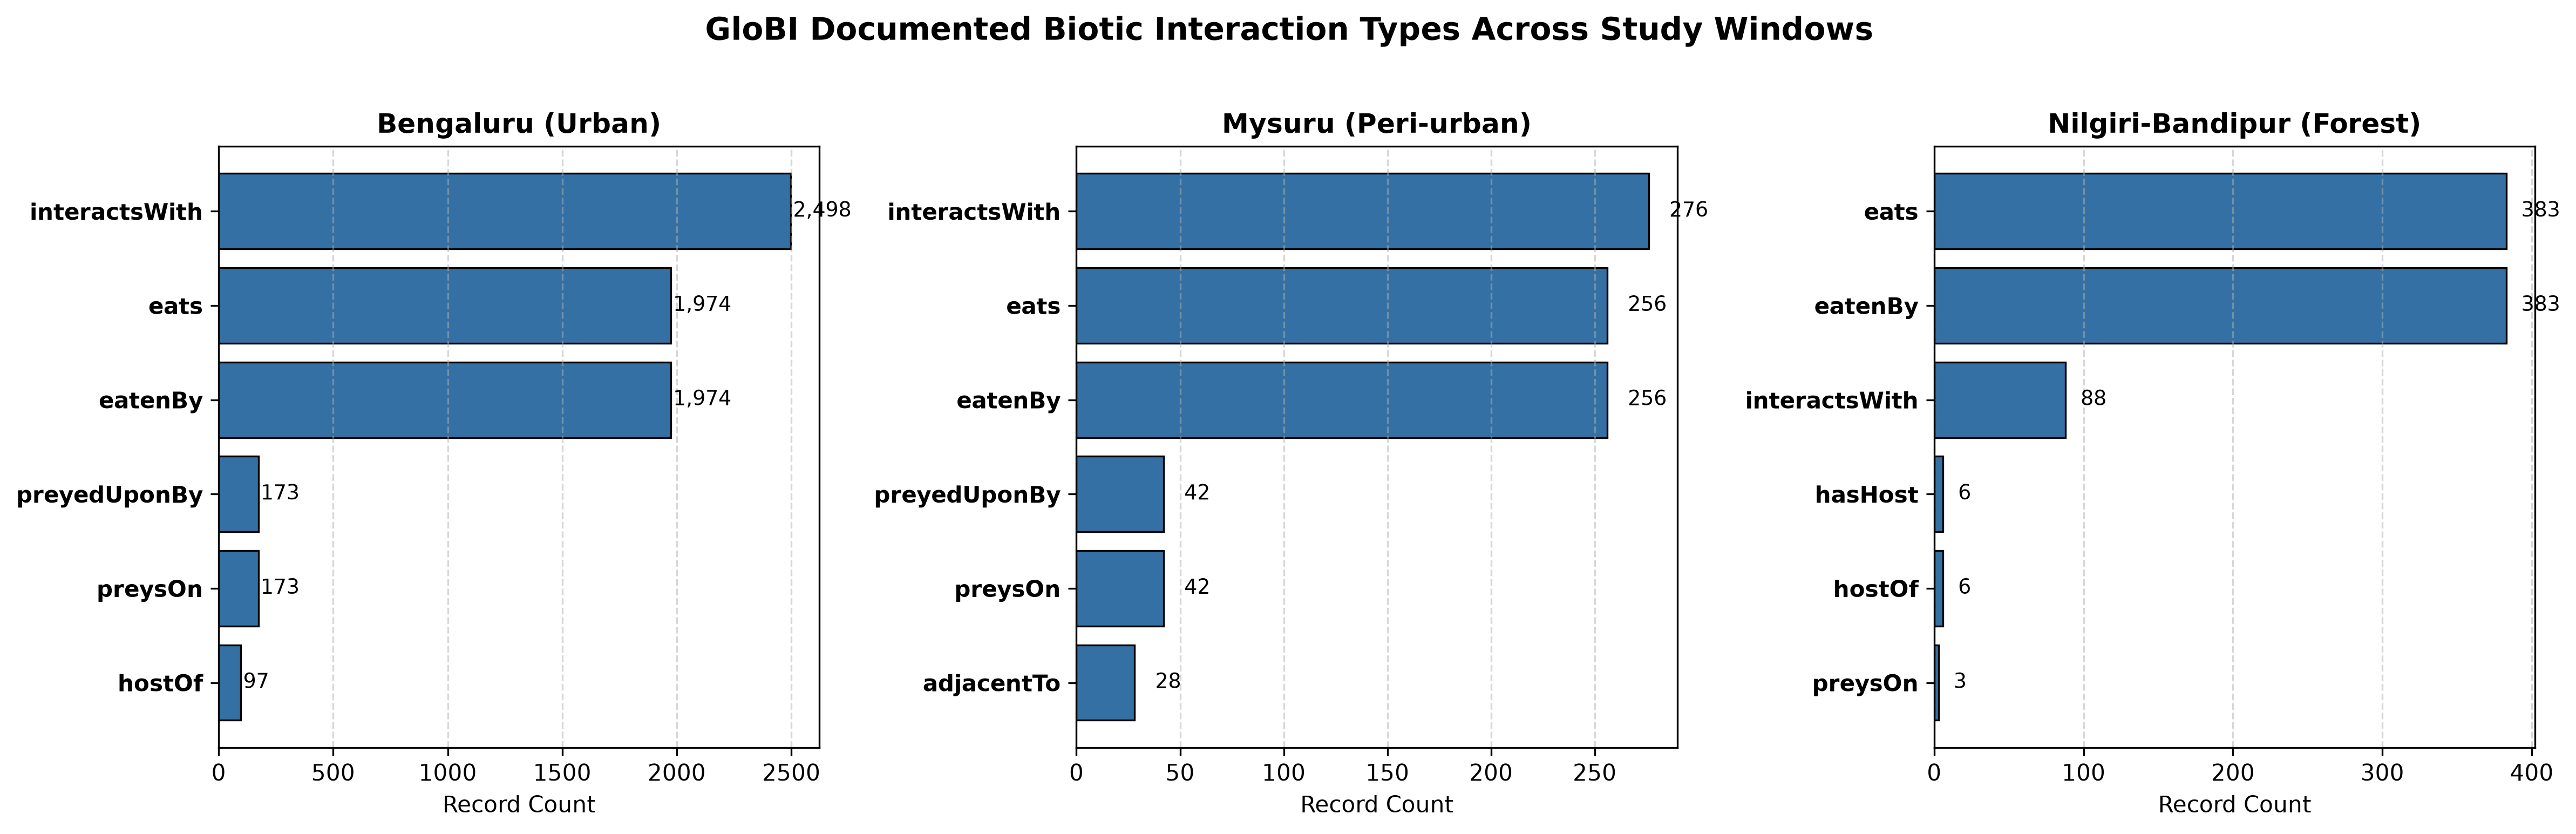

In [5]:
# Display Figure: Interaction Types Breakdown
fig_path = Path("../../reports/phase_4/figures/globi_interaction_types_breakdown.png")
if fig_path.exists():
    from IPython.display import Image
    display(Image(filename=str(fig_path)))

### 4. Temporal Alignment with 2012–2024 Baseline
Our remote sensing (VIIRS) and GBIF occurrence datasets cover 2012–2024.
How well do empirical GloBI interaction observations align with this window?
- **Bengaluru**: 4,482 records (62.0%) fall in 2012–2024; 2,092 in 2025/2026; 590 pre-2012.
- **Mysuru**: 574 records (60.7%) fall in 2012–2024; 212 in 2025/2026; 148 pre-2012.
- **Nilgiri–Bandipur**: 104 records (11.9%) fall in 2012–2024; 752 records (85.8%) date from 2006/2008!
  - *Scientific Insight*: The vast majority of forest interactions in Nilgiri-Bandipur originate from the published **CarniDIET** survey (Middleton et al.), which conducted carnivore scat analyses in 2006 and 2008. These represent genuine, high-quality trophic interactions (Tiger, Leopard, Dhole) that can serve as a static regional trophic scaffold.

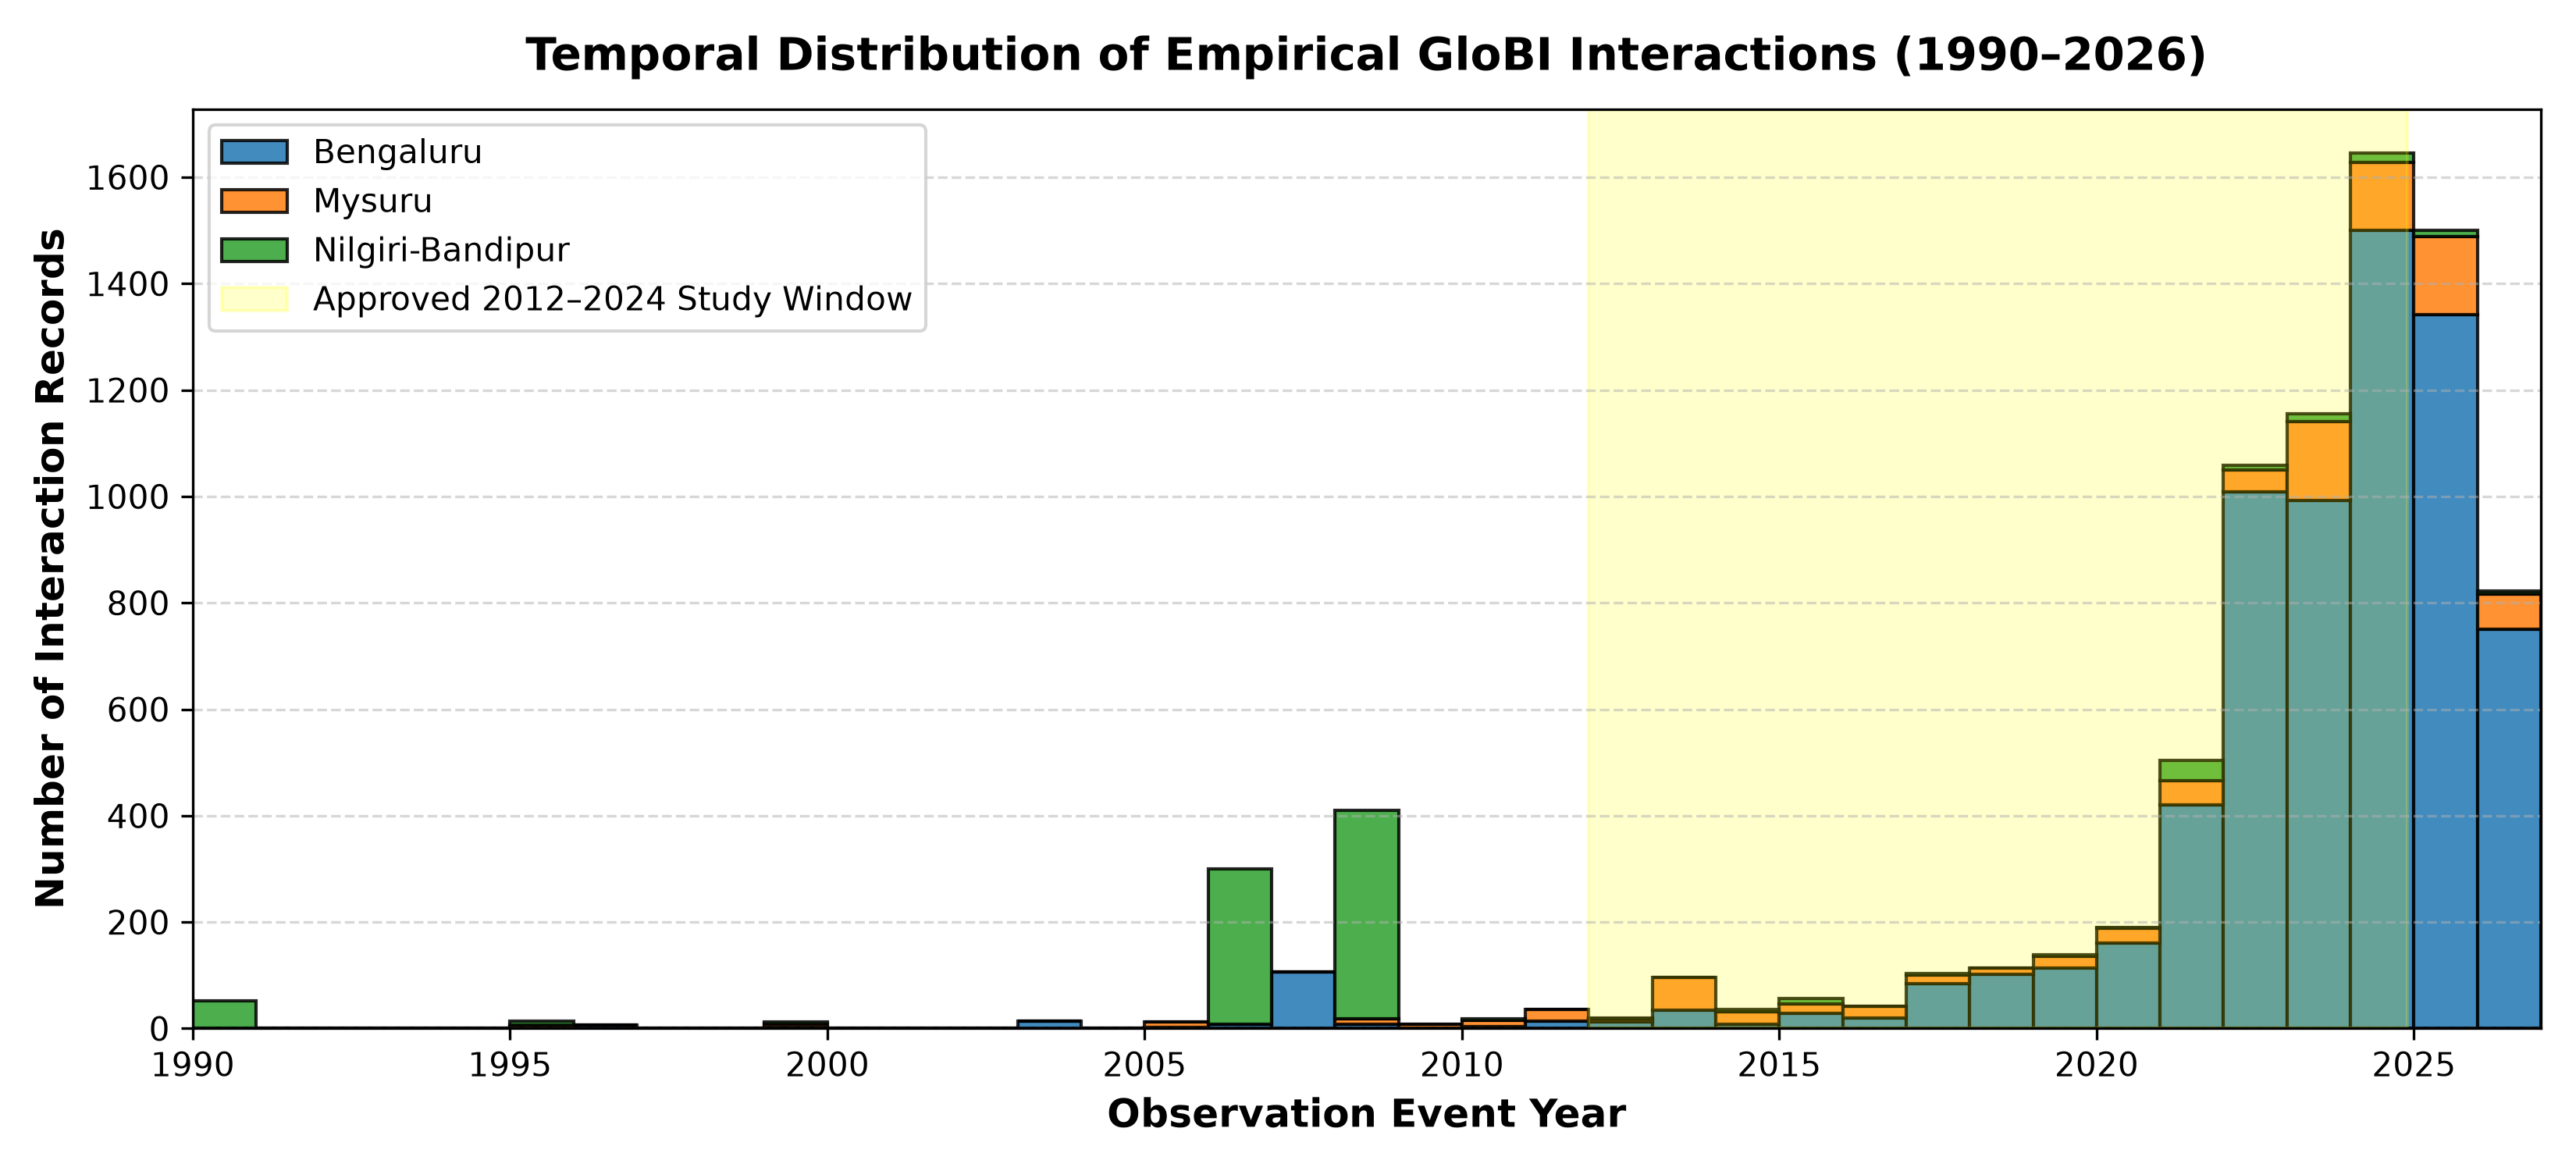

In [6]:
# Display Figure: Temporal Distribution
fig_path = Path("../../reports/phase_4/figures/globi_temporal_distribution.png")
if fig_path.exists():
    from IPython.display import Image
    display(Image(filename=str(fig_path)))

### 5. Summary of Regional Availability
- **Total empirical records retrieved**: 9,048 across the three bounding boxes.
- **Records inside 50 km study polygons**: 9,044 (99.96%).
- **Coordinate completeness**: 100.0% of records have valid decimal latitude and longitude.
- **Temporal completeness**: >98.7% across all three regions have documented event dates.
- **Trophic coverage**: Broad coverage of herbivory, predation, pollination, and parasitism across taxa.